# Prediction and simulation

What a fitted mixed model says about *new* observations:

* `predict()` with `newdata`, and the choice of which random effects to condition on:
  `re_form=None` (R's `re.form = NULL`, all of them: subject-level predictions),
  `re_form="NA"` (R's `re.form = NA`, none: population-level predictions) or a partial
  formula such as `"~(1|plate)"`; `allow_new_levels` for groups not seen in the fit;
  `type="link"` / `"response"` for GLMMs;
* standard errors of predictions, `predict(..., se_fit=True)` (R's `se.fit = TRUE`);
* population-level versus subject-level prediction curves;
* `simulate()`: unconditional (new random effects) and conditional on the estimated random
  effects (`use_u=True`);
* a parametric bootstrap with `bootMer()`;
* power analysis by simulation: `simulate()` from a *formula* with assumed parameters
  (no fitted model), then refit each simulated data set.

## Source

* lme4 help pages [`?predict.merMod`](https://github.com/lme4/lme4/blob/master/man/predict.merMod.Rd),
  [`?simulate.merMod`](https://github.com/lme4/lme4/blob/master/man/simulate.merMod.Rd),
  [`?bootMer`](https://github.com/lme4/lme4/blob/master/man/bootMer.Rd) and
  [`?simulate.formula`](https://github.com/lme4/lme4/blob/master/R/simulate.formula.R)
  (local copies in `upstream/lme4/man/` and `upstream/lme4/R/`);
* the lme4 tests [`tests/predsim.R`](https://github.com/lme4/lme4/blob/master/tests/predsim.R)
  and [`tests/simulate.R`](https://github.com/lme4/lme4/blob/master/tests/simulate.R);
* the "simulate and refit" approach to power analysis, as in the
  [GLMM FAQ](https://bbolker.github.io/mixedmodels-misc/glmmFAQ.html) and the
  `simr` package.

The R code (the full reference script is `examples/r/06_prediction_and_simulation.R`):

```r
library(lme4)
fm1 <- lmer(Reaction ~ Days + (Days | Subject), sleepstudy)
pop  <- data.frame(Days = 0:9)
predict(fm1, newdata = pop, re.form = NA, se.fit = TRUE)          # population level
subj <- expand.grid(Days = 0:9, Subject = factor(c("308", "309", "335")))
predict(fm1, newdata = subj, se.fit = TRUE)                       # subject level
newsubj <- data.frame(Days = c(0, 5, 9, 0, 5, 9),
                      Subject = factor(c("308", "308", "308", "new", "new", "new")))
predict(fm1, newdata = newsubj, allow.new.levels = TRUE, se.fit = TRUE)

fm3 <- lmer(diameter ~ 1 + (1 | plate) + (1 | sample), Penicillin)
predict(fm3, re.form = ~ (1 | plate))                             # partial conditioning

gm1 <- glmer(cbind(incidence, size - incidence) ~ period + (1 | herd),
             data = cbpp, family = binomial)
pp <- data.frame(period = factor(1:4))
predict(gm1, newdata = pp, re.form = NA, type = "response", se.fit = TRUE)

simulate(fm1, nsim = 5)                       # unconditional
simulate(fm1, nsim = 2000, use.u = TRUE)      # conditional on the random effects
b1 <- bootMer(fm1, fixef, nsim = 200, seed = 101)

## power analysis: simulate from a formula with assumed parameters, refit
design <- expand.grid(Days = 0:9, Subject = factor(1:20))
pars <- list(beta = c(250, 3), theta = c(25/26, 0, 6/26), sigma = 26)
ysim <- simulate(~ Days + (Days | Subject), nsim = 200, seed = 2024,
                 newdata = design, newparams = pars, family = gaussian)
tvals <- sapply(ysim, function(y) {
    design$Reaction <- y
    coef(summary(lmer(Reaction ~ Days + (Days | Subject), design)))["Days", "t value"]
})
mean(abs(tvals) > 2)
```

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.testing import assert_allclose

import lme4
from lme4 import lmer, glmer, bootMer, binomial, load_dataset, simulate_formula

with open("reference/06_prediction_and_simulation.json") as f:
    ref = json.load(f)
sleepstudy = load_dataset("sleepstudy")

## 1. Linear mixed model: population- and subject-level predictions

`re_form="NA"` sets all random effects to zero (the "typical subject"); the default
`re_form=None` adds the conditional modes of the subject's random effects.

In [2]:
fm1 = lmer("Reaction ~ Days + (Days | Subject)", sleepstudy)
print(fm1.fixef())

pop = pd.DataFrame({"Days": np.arange(10)})
p_pop = fm1.predict(newdata=pop, re_form="NA", se_fit=True)
pd.DataFrame({"Days": pop.Days, "fit": p_pop["fit"], "se.fit": p_pop["se.fit"]})

(Intercept)    251.405105
Days            10.467286
dtype: float64


,Days,fit,se.fit
0,0,251.405105,6.824597
1,1,261.872391,6.786929
2,2,272.339677,7.094267
3,3,282.806963,7.705438
4,4,293.274249,8.555575
5,5,303.741535,9.581277
6,6,314.208821,10.732326
7,7,324.676107,11.972623
8,8,335.143393,13.277180
9,9,345.610678,14.628816


`se_fit=True` returns a dict with the fit and its standard error (R returns
`list(fit, se.fit)`). The standard error comes from the joint covariance matrix of the
conditional modes and the fixed effects (R's internal `vcov_full()`), so for the
population-level prediction it is just $\sqrt{x^\top \operatorname{Var}(\hat\beta)\, x}$:

In [3]:
X = np.column_stack([np.ones(10), np.arange(10)])
se_wald = np.sqrt(np.einsum("ij,jk,ik->i", X, fm1.vcov().values, X))
assert_allclose(p_pop["se.fit"].values, se_wald, rtol=1e-10)

In [4]:
subjects = ["308", "309", "335"]
subj = pd.DataFrame({"Days": np.tile(np.arange(10), 3),
                     "Subject": pd.Categorical(np.repeat(subjects, 10))})
p_subj = fm1.predict(newdata=subj, se_fit=True)
subj.assign(fit=p_subj["fit"].values, se=p_subj["se.fit"].values).head(12)

,Days,Subject,fit,se
0,0,308,253.663656,12.254811
1,1,308,273.329918,10.543385
2,2,308,292.996179,9.113832
3,3,308,312.662441,8.116482
4,4,308,332.328703,7.720687
5,5,308,351.994964,8.016054
6,6,308,371.661226,8.934295
7,7,308,391.327488,10.310312
8,8,308,410.993750,11.987485
9,9,308,430.660011,13.856893


### Groups not seen in the fit

By default a new level is an error, as in R. With `allow_new_levels=True` its random
effects are set to zero, so the prediction (and its standard error) for a new subject
is the population-level one.

In [5]:
newsubj = pd.DataFrame({"Days": [0, 5, 9, 0, 5, 9],
                        "Subject": pd.Categorical(["308"] * 3 + ["new"] * 3)})
try:
    fm1.predict(newdata=newsubj)
except ValueError as e:
    new_error = str(e)
    print("Error:", new_error)
p_new = fm1.predict(newdata=newsubj, allow_new_levels=True, se_fit=True)
newsubj.assign(fit=p_new["fit"].values, se=p_new["se.fit"].values)

Error: new levels detected in newdata: new


,Days,Subject,fit,se
0,0,308,253.663656,12.254811
1,5,308,351.994964,8.016054
2,9,308,430.660011,13.856893
3,0,new,251.405105,6.824597
4,5,new,303.741535,9.581277
5,9,new,345.610678,14.628816


### Prediction curves

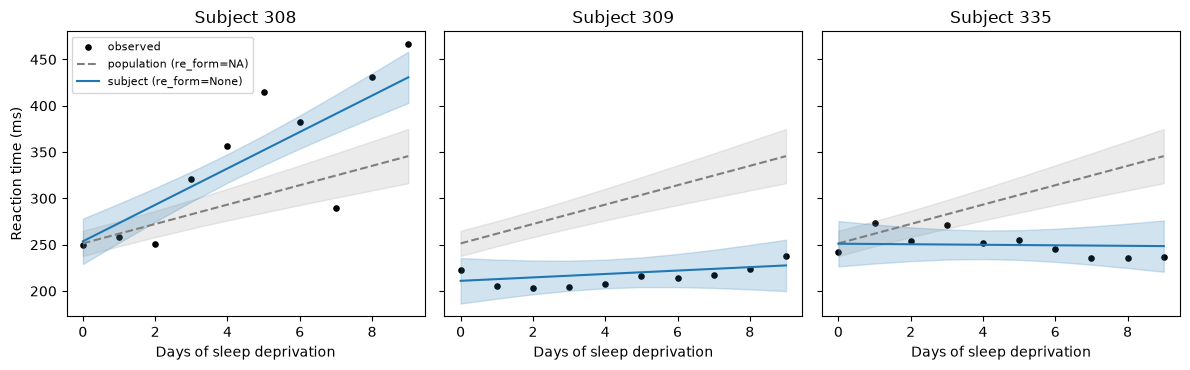

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
pop_fit, pop_se = p_pop["fit"].values, p_pop["se.fit"].values
for ax, s in zip(axes, subjects):
    d = sleepstudy[sleepstudy.Subject == s]
    sel = (subj.Subject == s).values
    f, se = p_subj["fit"].values[sel], p_subj["se.fit"].values[sel]
    ax.scatter(d.Days, d.Reaction, s=14, color="k", label="observed")
    ax.plot(pop.Days, pop_fit, color="tab:gray", ls="--", label="population (re_form=NA)")
    ax.fill_between(pop.Days, pop_fit - 2 * pop_se, pop_fit + 2 * pop_se, color="tab:gray", alpha=0.15)
    ax.plot(pop.Days, f, color="tab:blue", label="subject (re_form=None)")
    ax.fill_between(pop.Days, f - 2 * se, f + 2 * se, color="tab:blue", alpha=0.2)
    ax.set_title(f"Subject {s}")
    ax.set_xlabel("Days of sleep deprivation")
axes[0].set_ylabel("Reaction time (ms)")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Check against R

In [7]:
assert_allclose(fm1.fixef().values, ref["fm1_fixef"], rtol=1e-6)
assert_allclose(fm1.predict().values, ref["fm1_fitted"], rtol=1e-6)
assert_allclose(fm1.predict(re_form="NA").values, ref["fm1_pred_NA"], rtol=1e-6)
assert_allclose(p_pop["fit"].values, ref["pop_fit"], rtol=1e-6)
assert_allclose(p_pop["se.fit"].values, ref["pop_se"], rtol=1e-6)
assert_allclose(p_subj["fit"].values, ref["subj_fit"], rtol=1e-6)
assert_allclose(p_subj["se.fit"].values, ref["subj_se"], rtol=1e-6)
assert_allclose(p_new["fit"].values, ref["new_fit"], rtol=1e-6)
assert_allclose(p_new["se.fit"].values, ref["new_se"], rtol=1e-6)
assert new_error == ref["new_error"]
assert_allclose(fm1.predict(se_fit=True)["se.fit"].values, ref["fm1_se_all"], rtol=1e-6)
print("LMM predictions and standard errors agree with R")

LMM predictions and standard errors agree with R


## 2. Conditioning on some of the random effects: `re_form` as a formula

With crossed random effects (Penicillin: `plate` and `sample`) we can condition on one
factor only.

In [8]:
fm3 = lmer("diameter ~ 1 + (1 | plate) + (1 | sample)", load_dataset("Penicillin"))
pen = pd.DataFrame({
    "full": fm3.predict().values,
    "plate only": fm3.predict(re_form="~(1|plate)").values,
    "sample only": fm3.predict(re_form="~(1|sample)").values,
    "none": fm3.predict(re_form="NA").values})
pen_plate_se = fm3.predict(re_form="~(1|plate)", se_fit=True)["se.fit"].values
pen.head()

,full,plate only,sample only,none
0,25.963827,23.776769,25.159281,22.972222
1,22.766293,23.776769,21.961746,22.972222
2,25.714669,23.776769,24.910122,22.972222
3,23.679874,23.776769,22.875327,22.972222
4,23.762927,23.776769,22.958380,22.972222


In [9]:
assert_allclose(pen["full"], ref["pen_full"], rtol=1e-6)
assert_allclose(pen["plate only"], ref["pen_plate"], rtol=1e-6)
assert_allclose(pen["sample only"], ref["pen_sample"], rtol=1e-6)
assert_allclose(pen["none"], ref["pen_NA"], rtol=1e-6)
# the standard errors depend on theta, which nloptwrap locates only to ~1e-5 here
# (R: 1.5396756, 3.5125189; Python: 1.5396764, 3.5124920), hence the looser tolerance
assert_allclose(pen_plate_se, ref["pen_plate_se"], rtol=1e-4)
print("partial re.form predictions agree with R")

partial re.form predictions agree with R


## 3. GLMM: link and response scale

For a GLMM, `type="link"` (default) gives the linear predictor and `type="response"`
applies the inverse link. On the response scale the standard error is obtained by the
delta method (multiplied by $|d\mu/d\eta|$); R warns that for GLMMs it is an
approximation, and so does Python.

In [10]:
cbpp = load_dataset("cbpp")
gm1 = glmer("cbind(incidence, size - incidence) ~ period + (1 | herd)", cbpp, family=binomial)
pp = pd.DataFrame({"period": pd.Categorical(["1", "2", "3", "4"])})
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    g_link = gm1.predict(newdata=pp, re_form="NA", se_fit=True)
    g_resp = gm1.predict(newdata=pp, re_form="NA", type="response", se_fit=True)
print(w[0].message)
pd.DataFrame({"period": pp.period, "eta": g_link["fit"], "se(eta)": g_link["se.fit"],
              "prob": g_resp["fit"], "se(prob)": g_resp["se.fit"]})

se.fit computation uses an approximation to estimate the sampling distribution of the parameters


,period,eta,se(eta),prob,se(prob)
0,1,-1.398532,0.227893,0.198049,0.036195
1,2,-2.390848,0.310303,0.083873,0.023843
2,3,-2.527196,0.330777,0.073973,0.022659
3,4,-2.978848,0.432644,0.048391,0.019923


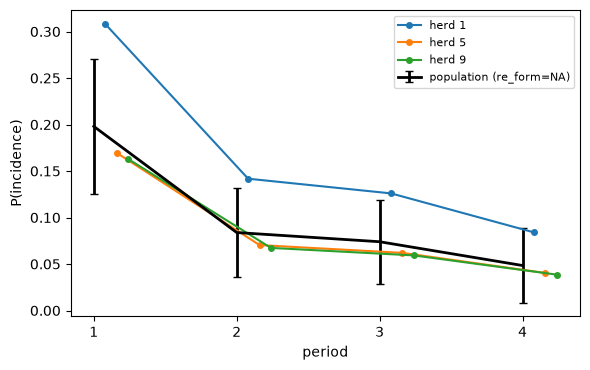

In [11]:
hp = pd.DataFrame({"period": pd.Categorical(np.tile(["1", "2", "3", "4"], 3)),
                   "herd": pd.Categorical(np.repeat(["1", "5", "9"], 4))})
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    g_herd = gm1.predict(newdata=hp, type="response", se_fit=True)

fig, ax = plt.subplots(figsize=(6, 3.8))
x = np.arange(1, 5)
ax.errorbar(x, g_resp["fit"], yerr=2 * g_resp["se.fit"], color="k", lw=2, capsize=3,
            label="population (re_form=NA)")
for k, h in enumerate(["1", "5", "9"]):
    sel = slice(4 * k, 4 * k + 4)
    ax.plot(x + 0.08 * (k + 1), g_herd["fit"].values[sel], "o-", ms=4, label=f"herd {h}")
ax.set_xticks(x)
ax.set_xlabel("period")
ax.set_ylabel("P(incidence)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
assert_allclose(gm1.predict().values, ref["gm1_link"], rtol=1e-5)
assert_allclose(gm1.predict(type="response").values, ref["gm1_resp"], rtol=1e-5)
assert_allclose(g_link["fit"].values, ref["gm1_pop_link"], rtol=1e-5)
assert_allclose(g_resp["fit"].values, ref["gm1_pop_resp"], rtol=1e-5)
assert_allclose(g_link["se.fit"].values, ref["gm1_pop_se_link"], rtol=1e-5)
assert_allclose(g_resp["se.fit"].values, ref["gm1_pop_se_resp"], rtol=1e-5)
assert_allclose(g_herd["fit"].values, ref["gm1_herd_resp"], rtol=1e-5)
assert_allclose(g_herd["se.fit"].values, ref["gm1_herd_se_resp"], rtol=1e-5)
print("GLMM predictions and standard errors agree with R")

GLMM predictions and standard errors agree with R


(The GLMM is fitted by numerical optimization of the Laplace approximation, so the
tolerance is `1e-5` rather than `1e-6`.)

## 4. `simulate()`: unconditional and conditional

`simulate(fm1)` draws new random effects and new residuals (R's default `re.form = NA`);
`use_u=True` keeps the random effects at their conditional modes and only draws new
residuals. Python uses numpy's random generator, so the draws cannot match R's; we check
distributional properties instead:

* unconditional: the variance across simulations at each `Days` value should be the
  model's marginal variance $\operatorname{Var}(b_0) + 2d\operatorname{Cov}(b_0,b_1) +
  d^2\operatorname{Var}(b_1) + \sigma^2$ (computed in R);
* conditional: the mean over simulations should be close to the fitted values.

In [13]:
s1 = fm1.simulate(nsim=5, seed=101)
print(s1.shape)
s1.head()

(180, 5)


,sim_1,sim_2,sim_3,sim_4,sim_5
0,197.380003,319.594173,215.393233,284.191345,269.400547
1,261.638337,274.522215,246.791519,233.602608,284.720739
2,215.703889,288.617403,250.371847,262.627106,276.013958
3,253.403543,308.611937,275.854654,250.224283,304.812358
4,238.080612,342.485585,303.673117,255.918637,330.941330


In [14]:
nsim = 2000
s_unc = fm1.simulate(nsim=nsim, seed=1)
s_cond = fm1.simulate(nsim=nsim, seed=1, use_u=True)

v_by_day = s_unc.groupby(sleepstudy.Days.values).apply(lambda d: d.values.var(ddof=1))
pd.DataFrame({"empirical": v_by_day.values, "theoretical (R)": ref["marg_var"]},
             index=pd.Index(range(10), name="Days"))

,empirical,theoretical (R)
Days,,
0,1260.663186,1267.040166
1,1310.461365,1321.320699
2,1439.320814,1445.744660
3,1624.546986,1640.312050
4,1879.885100,1905.022869
5,2223.311632,2239.877117
6,2610.346143,2644.874794
7,3086.922953,3120.015900
8,3618.415746,3665.300434


In [15]:
# Structure: same as R's simulate() (180 x nsim)
assert list(s1.shape) == ref["sim_dim"]
# Unconditional: each day's variance pools 18 subjects x 2000 draws; the sampling
# fluctuation of the subject effects dominates, so allow 10%
assert_allclose(v_by_day.values, ref["marg_var"], rtol=0.10)
# Conditional: mean of 2000 draws, SE = sigma/sqrt(2000) ~ 0.57 ms; R gives max error
cond_err = np.max(np.abs(s_cond.mean(axis=1).values - fm1.fitted().values))
print(f"max |mean(sim) - fitted|: Python {cond_err:.3f}, R {ref['sim_cond_mean_err']:.3f}")
assert cond_err < 5 * ref["sigma"] / np.sqrt(nsim)

max |mean(sim) - fitted|: Python 1.561, R 1.513


## 5. Parametric bootstrap with `bootMer()`

The statistic here is the vector of fixed effects. The bootstrap standard errors are
random; we compare them with R's bootstrap standard errors and with the Wald standard
errors loosely (with 200 replicates the standard error of a standard deviation is
about 5%).

In [16]:
b1 = bootMer(fm1, lambda m: m.fixef(), nsim=200, seed=101)
print(b1)
print(b1.confint())

boundary (singular) fit: see help('isSingular')
boundary (singular) fit: see help('isSingular')


boundary (singular) fit: see help('isSingular')


boundary (singular) fit: see help('isSingular')
boundary (singular) fit: see help('isSingular')



PARAMETRIC BOOTSTRAP

Bootstrap Statistics :
       original      bias  std. error
t1*  251.405105 -0.664790    6.290348
t2*   10.467286  0.011652    1.452718

                  2.5 %      97.5 %
(Intercept)  237.384848  263.435372
Days           7.528752   13.357591


boundary (singular) fit: see help('isSingular')


In [17]:
boot_sd = b1.t.std(axis=0, ddof=1)
wald_se = np.sqrt(np.diag(np.reshape(ref["fm1_vcov"], (2, 2))))
print(pd.DataFrame({"boot SE (Python)": boot_sd, "boot SE (R)": ref["boot_sd"],
                    "Wald SE (R)": wald_se}, index=fm1.fixef().index))
assert_allclose(b1.t0.values, ref["boot_t0"], rtol=1e-6)   # deterministic
assert_allclose(boot_sd, ref["boot_sd"], rtol=0.25)
assert_allclose(boot_sd, wald_se, rtol=0.25)

             boot SE (Python)  boot SE (R)  Wald SE (R)
(Intercept)          6.290348     6.790263     6.824597
Days                 1.452718     1.675204     1.545790


## 6. Power analysis by simulation

The classic workflow: specify a design and *assumed* parameter values, simulate responses
from the model, refit each data set, and count how often the effect is detected.
`simulate_formula()` (R's `simulate(~ formula, newdata=, newparams=, family=)`) simulates
from a one-sided formula without a fitted model.

The design is 20 subjects measured on days 0–9, with intercept 250 ms, slope 3 ms/day,
random-intercept SD 25, random-slope SD 6 (uncorrelated) and residual SD 26. `theta` holds
the elements of the relative Cholesky factor of the random-effects covariance
(SD/σ on the diagonal). The "detection" criterion is |t| > 2.

In [18]:
design = pd.DataFrame({"Days": np.tile(np.arange(10), 20),
                       "Subject": pd.Categorical(np.repeat([str(i) for i in range(1, 21)], 10),
                                                 categories=[str(i) for i in range(1, 21)])})
pars = dict(beta=[250, 3], theta=[25 / 26, 0, 6 / 26], sigma=26)
nsim_pow = 200
ysim = simulate_formula("~ Days + (Days | Subject)", nsim=nsim_pow, seed=2024,
                        newdata=design, newparams=pars)

def t_slope(y):
    d = design.assign(Reaction=y)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # occasional singular fits / convergence notes
        m = lmer("Reaction ~ Days + (Days | Subject)", d)
    return m.fixef()["Days"] / np.sqrt(m.vcov().values[1, 1])

tvals = np.array([t_slope(ysim[c].values) for c in ysim.columns])
power = np.mean(np.abs(tvals) > 2)
print(f"power (Python simulation): {power:.3f}")
print(f"power (R simulation):      {ref['power_R']:.3f}")
print(f"approximate Wald power:    {ref['power_wald']:.3f}")

boundary (singular) fit: see help('isSingular')
boundary (singular) fit: see help('isSingular')


boundary (singular) fit: see help('isSingular')


power (Python simulation): 0.525
power (R simulation):      0.500
approximate Wald power:    0.507


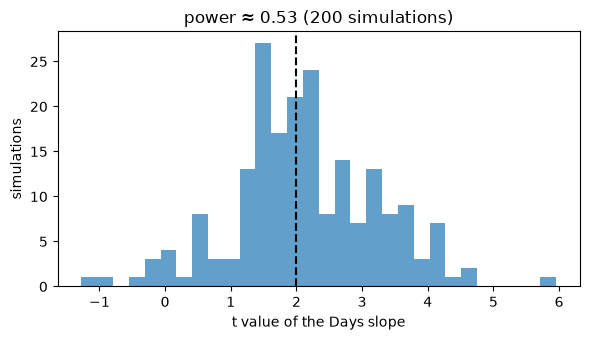

In [19]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(tvals, bins=30, color="tab:blue", alpha=0.7)
ax.axvline(2, color="k", ls="--")
ax.set_xlabel("t value of the Days slope")
ax.set_ylabel("simulations")
ax.set_title(f"power ≈ {power:.2f} ({nsim_pow} simulations)")
plt.tight_layout()
plt.show()

The simulated power is a binomial proportion: with 200 simulations its standard error is
about $\sqrt{0.5 \cdot 0.5/200} \approx 0.035$, so the Python and R estimates (different
random streams) must agree within a few standard errors, and both with the large-sample
approximation.

In [20]:
se_pow = np.sqrt(0.25 / nsim_pow)
assert abs(power - ref["power_R"]) < 4 * np.sqrt(2) * se_pow
assert abs(power - ref["power_wald"]) < 4 * se_pow
print("simulated power is consistent with R")

simulated power is consistent with R


## Summary

| quantity | agreement with R |
|---|---|
| predictions (`re_form` None / NA / partial, new levels, link/response) | rtol 1e-6 (LMM), 1e-5 (GLMM) |
| `se_fit` standard errors | rtol 1e-6 (LMM), 1e-5 (GLMM) |
| `simulate`, `bootMer`, power | random: checked through distributional properties |